In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bank Marketing — Exploratory Data Analysis

## Project Overview

This project aims to predict whether a customer will
subscribe to a bank term deposit based on demographic,
financial, and campaign-related features.

The objective of this notebook is to explore the dataset,
identify potential data quality issues, and investigate
relationships between features and the target variable.

In [2]:
df = pd.read_csv(
    "../data/raw/bank-full.csv",
    sep=";",
)

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:
df.shape

(45211, 17)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [7]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [8]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [9]:
df["job"].value_counts()

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

In [22]:
df["pdays"].head(10)

0   -1
1   -1
2   -1
3   -1
4   -1
5   -1
6   -1
7   -1
8   -1
9   -1
Name: pdays, dtype: int64

In [11]:
df["y"].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [12]:
df["y"].value_counts(normalize=True)

y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64

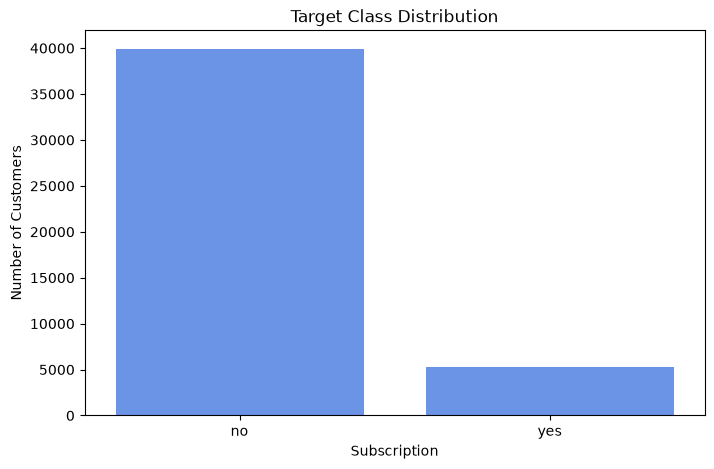

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="y"
)

plt.title("Target Class Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()

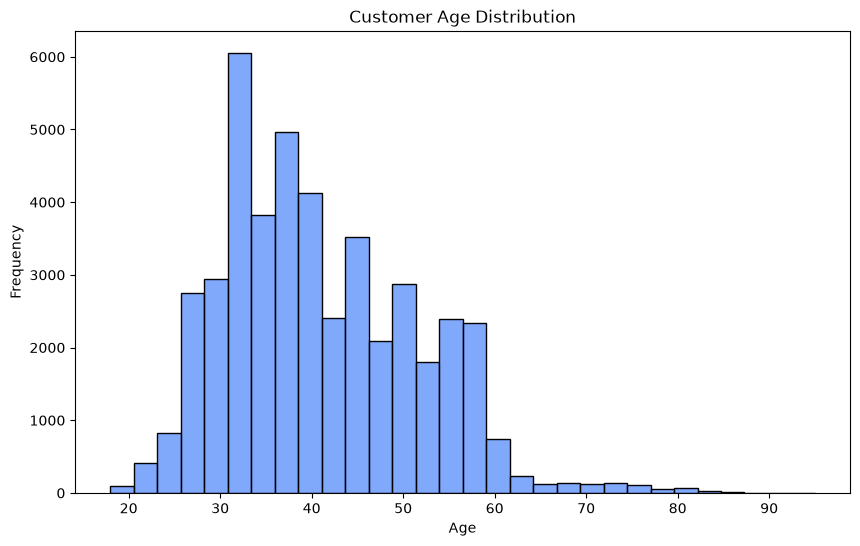

In [14]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="age",
    bins=30
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

In [16]:
duplicat_raws = df.duplicated().sum()
duplicat_raws

np.int64(0)

In [17]:
categorical_columns = df.select_dtypes(
    include=["object", "string"]
).columns

unknown_summary = pd.DataFrame({
    "unknown_count": (df[categorical_columns] == "unknown").sum(),
    "unknown_percentage": (
        (df[categorical_columns] == "unknown").mean() * 100
    ).round(2)
}).sort_values("unknown_count", ascending=False)

unknown_summary

,unknown_count,unknown_percentage
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
marital,0,0.00
default,0,0.00
housing,0,0.00
loan,0,0.00
month,0,0.00
y,0,0.00


## Initial Findings

### Observations supported by the notebook outputs

- The dataset contains 45,211 observations and 17 columns. Seven columns are integer-valued and ten are stored as strings.
- Pandas detected no null or `NaN` values. However, categorical values such as `unknown` are present and may represent unavailable information.
- The `job` column contains 288 `unknown` values, corresponding to approximately 0.64% of the dataset. The occurrence of `unknown` in the other categorical columns has not yet been quantified.
- The target variable is highly imbalanced: 39,922 observations (88.30%) belong to the `no` class, while 5,289 observations (11.70%) belong to the `yes` class. Therefore, accuracy alone will not be sufficient for evaluating future models.
- Customer age ranges from 18 to 95 years, with a median of 39 years. The middle 50% of customers are between 33 and 48 years old. The histogram shows a concentration of observations among working-age customers and a sparse right tail at older ages.
- Some numerical variables have maxima far above their third quartiles. For example, `balance` has a median of 448 and a maximum of 102,127, while `duration` has a median of 180 and a maximum of 4,918.
- At least 75% of the observations have `pdays` equal to -1, and at least 75% have `previous` equal to 0.

### Hypotheses and questions for further analysis

- The large ranges observed in `balance`, `duration`, `campaign`, and `previous` may indicate right-skewed distributions or influential extreme observations. Additional plots are required before deciding whether any treatment is necessary.
- The value `unknown` may represent missing or unavailable information, but this should be verified using the dataset documentation before recoding it.
- The meaning of `pdays = -1` should also be confirmed before treating it as an ordinary numerical value.
- No relationship between the predictors and the target has been established yet. Possible associations with age, job, balance, or campaign characteristics must be investigated in the next stage of the EDA.